In [4]:
%reload_ext autoreload
%autoreload 2
import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

sim_path = "/data-archive/petermann-thermal-models/sim-ensemble/"
small_data_path = ("/home/donglaiyang/Documents/"
                   "Georgia-Tech/Research/"
                   "petermann-basin-thermal-model/results/")
exp_path = (
    "/home/donglaiyang/Documents/Georgia-Tech/Research/"
    "petermann-basin-thermal-model/data/drainage-boundary/"
    "1.1-1.2-downsample-boundary.exp"
)

save_path = "../data/"

# Preparing data: Load ISSM simulation data

In [9]:
sim_path = "/data-archive/petermann-thermal-models/sim-ensemble/"
# Find files and extract the ensemble index from each filename.
files = list(Path(sim_path).glob("Eb_GHF_*.mat"))

def ensemble_index(path):
    return int(re.fullmatch(r"Eb_GHF_(\d+)\.mat", path.name).group(1))

files.sort(key=ensemble_index)

if not files:
    raise FileNotFoundError(f"No Eb_GHF_*.mat files found in {sim_path}")

# ensemble[ii] contains the data saved for simulation ii.
ensemble = {}

for file in files:
    ii = ensemble_index(file)
    output = loadmat(file, simplify_cells=True)["output"]

    ensemble[ii] = {
        field: np.asarray(output[field]).reshape(-1)
        for field in ("x_vertex", "y_vertex", "GHF", "Eb")
    }

print(f"Loaded {len(ensemble)} simulations.")

run_ids = np.array(sorted(ensemble))

x_vertex = ensemble[run_ids[0]]["x_vertex"]
y_vertex = ensemble[run_ids[0]]["y_vertex"]

# load ice thickness, assuming defined on the same x and y_vertex coordinates
thickness = loadmat(small_data_path + "ice_thickness.mat")["output"]["h"][0][0]
vel       = loadmat(small_data_path + "velocity.mat")["output"]["vel"][0][0]
Ts        = loadmat(small_data_path + "Ts.mat")["output"]["Ts"][0][0]
smb       = loadmat(small_data_path + "smb.mat")["output"]["smb"][0][0]


Loaded 500 simulations.


### Pixelate it

In [3]:
from src.PrepareData import pixelate_simulation, read_exp_boundary, pixelate_evidence

# load the domain boundary .exp file
boundary_xy = read_exp_boundary(exp_path)

pixelated = {
    ii: pixelate_simulation(
        sim,
        nx=256,
        ny=256,
        boundary_xy=boundary_xy,
    )
    for ii, sim in ensemble.items()
}

run_ids = np.array(sorted(pixelated))

GHF_pixels = np.stack([pixelated[ii]["GHF"] for ii in run_ids])
Eb_pixels = np.stack([pixelated[ii]["Eb"] for ii in run_ids])

# Shared mask and grid coordinates.
grid = pixelated[run_ids[0]]
mask = grid["mask"]
x_grid = grid["x"]
y_grid = grid["y"]

print("GHF shape:", GHF_pixels.shape)
print("Eb shape:", Eb_pixels.shape)
print("Mask shape:", mask.shape)

assert np.all(GHF_pixels[:, ~mask] == 0)
assert np.all(Eb_pixels[:, ~mask] == 0)

GHF shape: (500, 256, 256)
Eb shape: (500, 256, 256)
Mask shape: (256, 256)


In [10]:
# pixelate the ice thickness, velocity, smb, and Ts
h_vertex = {
    "x_vertex": x_vertex,
    "y_vertex": y_vertex,
    "h": thickness,
}
h_pixelated = pixelate_simulation(
    h_vertex,
    nx=256,
    ny=256,
    boundary_xy = boundary_xy,
)
vel_pixelated = pixelate_simulation(
    {"x_vertex": x_vertex, "y_vertex": y_vertex, "vel": vel},
    nx=256,
    ny=256,
    boundary_xy=boundary_xy,
)
smb_pixelated = pixelate_simulation(
    {"x_vertex": x_vertex, "y_vertex": y_vertex, "smb": smb},
    nx=256,
    ny=256,
    boundary_xy=boundary_xy,
)
Ts_pixelated = pixelate_simulation(
    {"x_vertex": x_vertex, "y_vertex": y_vertex, "Ts": Ts},
    nx=256,
    ny=256,
    boundary_xy=boundary_xy,
)

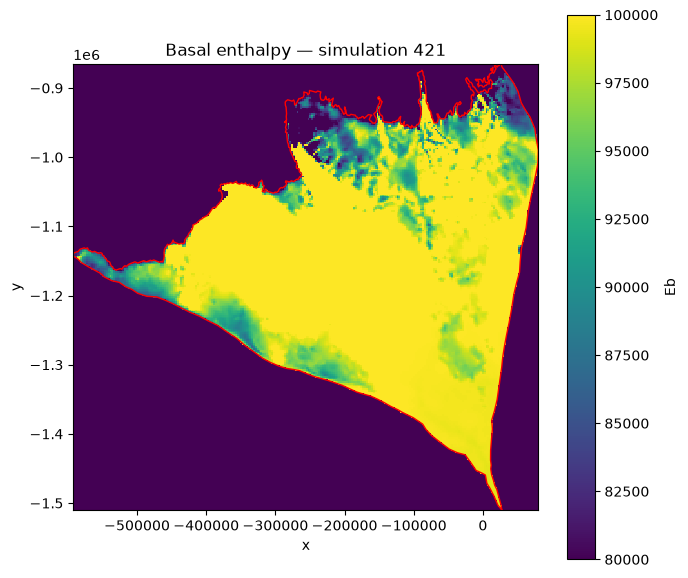

In [11]:
import matplotlib.pyplot as plt

ii = run_ids[420]
grid = pixelated[ii]

fig, ax = plt.subplots(figsize=(7, 6))

image = ax.pcolormesh(
    grid["x_edges"],
    grid["y_edges"],
    grid["Eb"],
    shading="flat",
    cmap="viridis",
    vmin=8e4, vmax=1e5
)

boundary = grid["boundary_xy"]
ax.plot(boundary[:, 0], boundary[:, 1], "r-", linewidth=1)

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Basal enthalpy — simulation {ii}")
fig.colorbar(image, ax=ax, label="Eb")

plt.tight_layout()
plt.show()


# Preparing data: Load basal thermal evidence

The data are scattered point locations in lat lon forms.

In [12]:
from pyproj import Transformer

evidence_path = "../data/raw-evidence/"
chu_thawed_path = evidence_path + "chu_thawed.csv"
chu_frozen_path = evidence_path + "chu_frozen.csv"

# load evidence data
chu_thawed_df = pd.read_csv(chu_thawed_path, skiprows=5)
chu_frozen_df = pd.read_csv(chu_frozen_path, skiprows=5)

# display the first few rows of the dataframes
chu_thawed_df.head()
chu_frozen_df.head()

chu_thawed_lat = chu_thawed_df['Lattitude'].values
chu_thawed_lon = chu_thawed_df['Longitude'].values
chu_frozen_lat = chu_frozen_df['Lattitude'].values
chu_frozen_lon = chu_frozen_df['Longitude'].values

transformer = Transformer.from_crs("EPSG:4326", "EPSG:3413")
chu_thawed_x, chu_thawed_y = transformer.transform(chu_thawed_lat, chu_thawed_lon)
chu_frozen_x, chu_frozen_y = transformer.transform(chu_frozen_lat, chu_frozen_lon)

In [13]:
from matplotlib.path import Path

# load jordan 2018 data (.tab) file
jordan_2018_path = evidence_path + "Jordan2018_fulldataset.csv"
jordan_2018_df = pd.read_csv(jordan_2018_path)
jordan_2018_df.head()

# col1: lat, col2: lon, col3: value (1 is water, 0 is no water, nan is no coverage)
jordan_lat = jordan_2018_df.iloc[:, 0]
jordan_lon = jordan_2018_df.iloc[:, 1]
jordan_value = jordan_2018_df.iloc[:, 2]

jordan_thawed = jordan_value == 1
jordan_frozen = jordan_value == 0
jordan_thawed_lat = jordan_lat[jordan_thawed]
jordan_thawed_lon = jordan_lon[jordan_thawed]
jordan_frozen_lat = jordan_lat[jordan_frozen]
jordan_frozen_lon = jordan_lon[jordan_frozen]

transformer = Transformer.from_crs("EPSG:4326", "EPSG:3413")
jordan_thawed_x, jordan_thawed_y = transformer.transform(jordan_thawed_lat, jordan_thawed_lon)
jordan_frozen_x, jordan_frozen_y = transformer.transform(jordan_frozen_lat, jordan_frozen_lon)

boundary = np.asarray(boundary, dtype=float)
jordan_thawed_x = np.asarray(jordan_thawed_x)
jordan_thawed_y = np.asarray(jordan_thawed_y)
jordan_frozen_x = np.asarray(jordan_frozen_x)
jordan_frozen_y = np.asarray(jordan_frozen_y)

# Explicitly close the polygon.
if not np.array_equal(boundary[0], boundary[-1]):
    boundary = np.vstack([boundary, boundary[0]])

polygon = Path(boundary)

# Test each (x, y) location.
points = np.column_stack([jordan_thawed_x, jordan_thawed_y])
inside_mask = polygon.contains_points(points)
print(f"Kept {inside_mask.sum()} of {len(inside_mask)} frozen points.")

# Keep only points inside the polygon.
jordan_thawed_x = jordan_thawed_x[inside_mask]
jordan_thawed_y = jordan_thawed_y[inside_mask]

points = np.column_stack([jordan_frozen_x, jordan_frozen_y])
inside_mask = polygon.contains_points(points)
jordan_frozen_x = jordan_frozen_x[inside_mask]
jordan_frozen_y = jordan_frozen_y[inside_mask]
print(f"Kept {inside_mask.sum()} of {len(inside_mask)} thawed points.")

Kept 706 of 7639 frozen points.
Kept 44785 of 284396 thawed points.


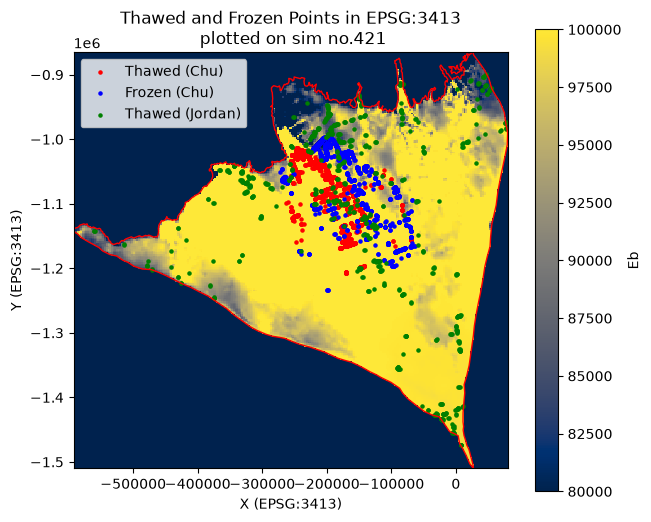

In [15]:
# plot them as scattered points 
fig, ax = plt.subplots(figsize=(7, 6))

image = ax.pcolormesh(
    grid["x_edges"],
    grid["y_edges"],
    grid["Eb"],
    shading="flat",
    cmap="cividis",
    vmin=8e4, vmax=1e5
)

boundary = grid["boundary_xy"]
ax.plot(boundary[:, 0], boundary[:, 1], "r-", linewidth=1)

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Basal enthalpy — simulation {ii}")
fig.colorbar(image, ax=ax, label="Eb")

ax.scatter(chu_thawed_x, chu_thawed_y, s = 5, color='red', label='Thawed (Chu)')
ax.scatter(chu_frozen_x, chu_frozen_y, s = 5, color='blue', label='Frozen (Chu)')
ax.scatter(jordan_thawed_x, jordan_thawed_y, s = 5, color='green', label='Thawed (Jordan)')
# ax.scatter(jordan_frozen_x, jordan_frozen_y, s = 5, color='green', label='Frozen (Jordan)')
ax.set_xlabel('X (EPSG:3413)')
ax.set_ylabel('Y (EPSG:3413)')
ax.set_title(f'Thawed and Frozen Points in EPSG:3413\n plotted on sim no.{ii}')
ax.legend()
plt.show()


# forming combined arrays
thawed_x = np.concatenate([chu_thawed_x, jordan_thawed_x])
thawed_y = np.concatenate([chu_thawed_y, jordan_thawed_y])
# we do not add frozen points from Jordan
frozen_x = chu_frozen_x
frozen_y = chu_frozen_y

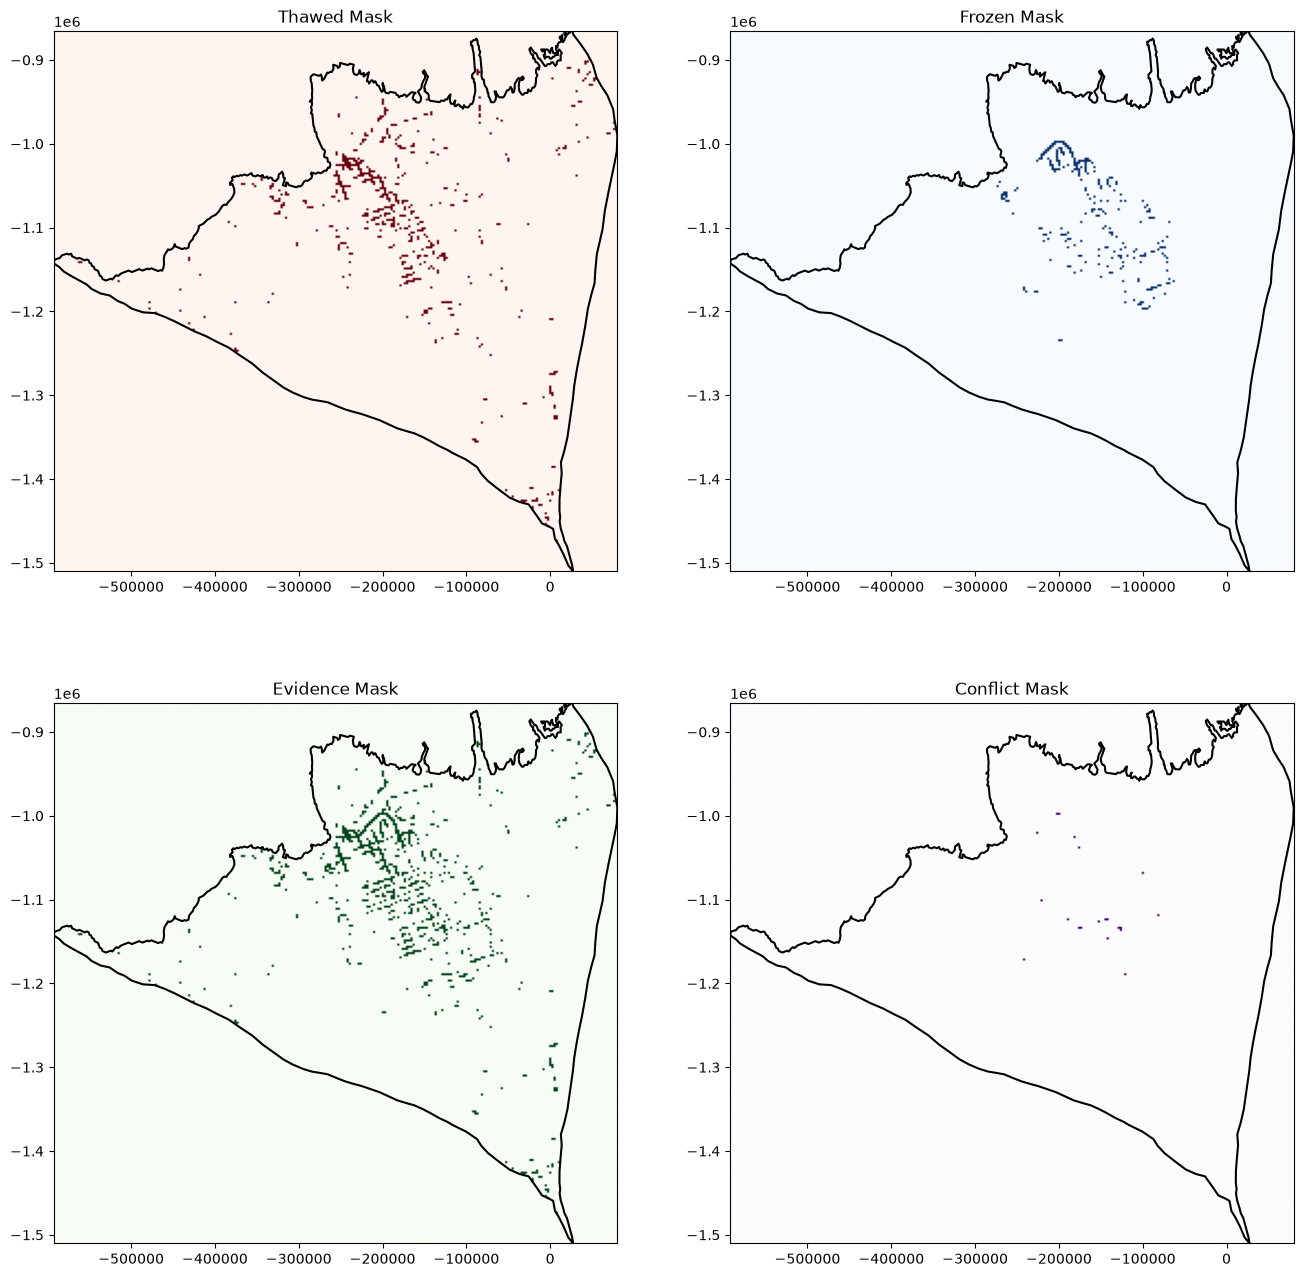

In [30]:
evidence_masks = pixelate_evidence(
    grid,
    thawed_x=thawed_x,
    thawed_y=thawed_y,
    frozen_x=frozen_x,
    frozen_y=frozen_y,
)

# get spatial extent for plotting
extent = [grid["x_edges"][0], grid["x_edges"][-1], grid["y_edges"][0], grid["y_edges"][-1]]

# visualize the masks
plt.figure(figsize=(16, 16))
plt.subplot(2,2,1)
plt.imshow(evidence_masks["thawed_mask"], cmap="Reds", origin="lower", extent=extent)
# add boundary
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Thawed Mask")

plt.subplot(2,2,2)
plt.imshow(evidence_masks["frozen_mask"], cmap="Blues", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Frozen Mask")

plt.subplot(2,2,3)
plt.imshow(evidence_masks["evidence_mask"], cmap="Greens", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Evidence Mask")

plt.subplot(2,2,4)
plt.imshow(evidence_masks["conflict_mask"], cmap="Purples", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Conflict Mask")

plt.show()


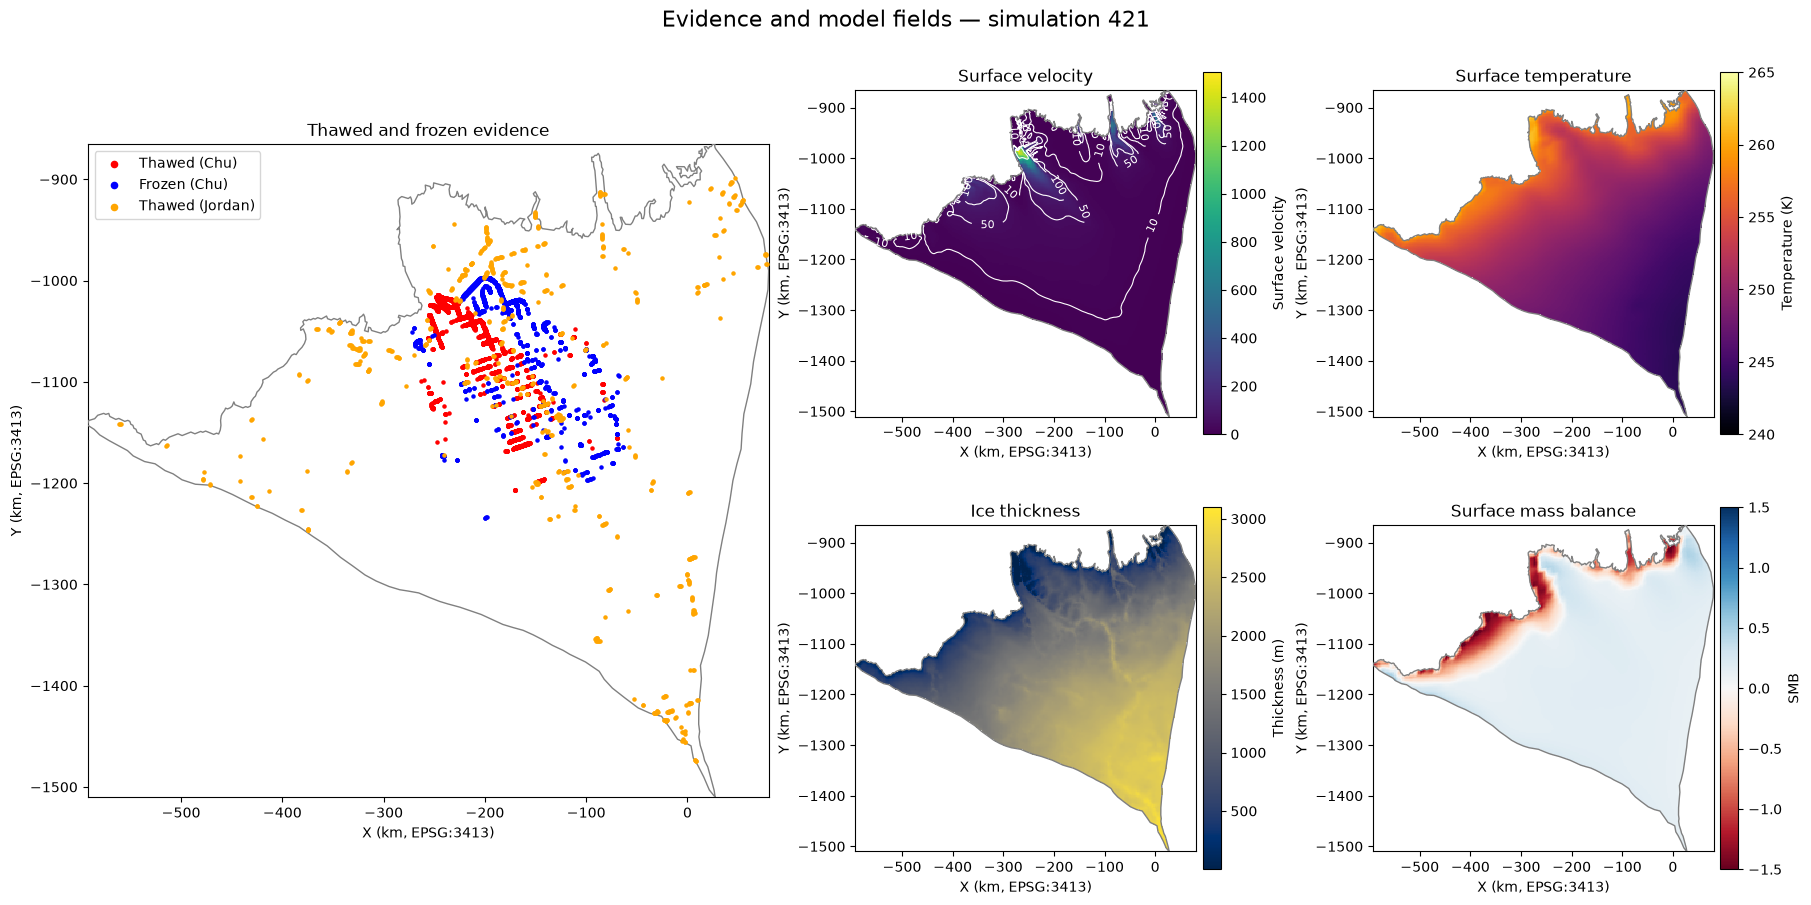

In [41]:
# Convert the existing extent and boundary coordinates from meters to km.
extent_km = [value / 1000.0 for value in extent]
boundary_km = np.asarray(boundary_xy) / 1000.0

fig = plt.figure(figsize=(18, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 4)

# Evidence panel occupies the left half: both rows, first two columns.
ax_evidence = fig.add_subplot(gs[:, :2])

# Four field panels occupy the right half.
ax_vel = fig.add_subplot(gs[0, 2])
ax_Ts = fig.add_subplot(gs[0, 3])
ax_h = fig.add_subplot(gs[1, 2])
ax_smb = fig.add_subplot(gs[1, 3])


def format_map(ax, title):
    """Apply the same boundary, extent, and coordinate units to each map."""
    ax.plot(
        boundary_km[:, 0],
        boundary_km[:, 1],
        color="grey",
        linewidth=1,
        zorder=3,
    )
    ax.set_xlim(extent_km[0], extent_km[1])
    ax.set_ylim(extent_km[2], extent_km[3])
    ax.set_aspect("equal")
    ax.set_xlabel("X (km, EPSG:3413)")
    ax.set_ylabel("Y (km, EPSG:3413)")
    ax.set_title(title)


# ------------------------------------------------------------------
# Evidence locations: scatter points only, with no field underneath.
# ------------------------------------------------------------------
ax_evidence.scatter(
    np.asarray(chu_thawed_x) / 1000.0,
    np.asarray(chu_thawed_y) / 1000.0,
    s=5,
    color="red",
    label="Thawed (Chu)",
    zorder=4,
)
ax_evidence.scatter(
    np.asarray(chu_frozen_x) / 1000.0,
    np.asarray(chu_frozen_y) / 1000.0,
    s=5,
    color="blue",
    label="Frozen (Chu)",
    zorder=4,
)
ax_evidence.scatter(
    np.asarray(jordan_thawed_x) / 1000.0,
    np.asarray(jordan_thawed_y) / 1000.0,
    s=5,
    color="orange",
    label="Thawed (Jordan)",
    zorder=4,
)

format_map(ax_evidence, "Thawed and frozen evidence")
ax_evidence.legend(loc="best", markerscale=2)


# ------------------------------------------------------------------
# Model fields: mask values outside the domain.
# Assumes the ice-thickness field in h_pixelated is named "h".
# ------------------------------------------------------------------
field_panels = [
    (ax_vel, vel_pixelated, "vel", "Surface velocity", "viridis", None, None),
    (ax_Ts, Ts_pixelated, "Ts", "Surface temperature", "inferno", 240, 265),
    (ax_h, h_pixelated, "h", "Ice thickness", "cividis", None, None),
    (ax_smb, smb_pixelated, "smb", "Surface mass balance", "RdBu", -1.5, 1.5),
]

colorbar_labels = {
    "vel": "Surface velocity",
    "Ts": "Temperature (K)",
    "h": "Thickness (m)",
    "smb": "SMB",
}

for ax, pixelated, key, title, cmap, vmin, vmax in field_panels:
    data = np.where(
        np.asarray(pixelated["mask"], dtype=bool),
        pixelated[key],
        np.nan,
    )

    image = ax.imshow(
        data,
        extent=extent_km,
        origin="lower",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
    )

    format_map(ax, title)

    fig.colorbar(
        image,
        ax=ax,
        label=colorbar_labels[key],
        shrink=0.85,
        pad=0.02,
    )

    if key == "vel":
        contours = ax.contour(
            np.ma.masked_invalid(data),
            levels=[10, 50, 100, 1000],
            colors="white",
            linewidths=0.8,
            extent=extent_km,
            origin="lower",
            zorder=2,
        )

        # Label the contour lines; remove this block for lines only.
        ax.clabel(
            contours,
            inline=True,
            fmt="%g",
            fontsize=8,
            colors="white",
        )


fig.suptitle(f"Evidence and model fields — simulation {ii}", fontsize=16)

# Save before plt.show() if needed:
fig.savefig("../figs/evidence_and_fields.png", dpi=300, bbox_inches="tight")

plt.show()


# A master plot
Showing basal thermal evidence, thickness, surface temperature, SMB, and surface velocity

# Prepare data: compute pressure melting point

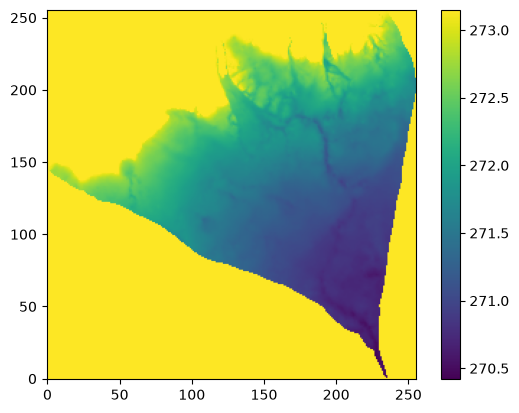

In [27]:
from ice import compute_pmp

pmp = compute_pmp(h_pixelated["h"])

plt.imshow(pmp, origin="lower")
plt.colorbar()
plt.show()

# Save the pixelated data to files

In [28]:
# save data
np.savez(
    save_path + "evidence_masks.npz",
    thawed_mask=evidence_masks["thawed_mask"],
    frozen_mask=evidence_masks["frozen_mask"],
    evidence_mask=evidence_masks["evidence_mask"],
    conflict_mask=evidence_masks["conflict_mask"],
)

np.savez(
    save_path + "grid.npz",
    x_edges=grid["x_edges"],
    y_edges=grid["y_edges"],
    mask=grid["mask"],
    x=grid["x"],
    y=grid["y"],
)


# simulation ensemble
np.savez(
    save_path + "simulations.npz",
    GHF=GHF_pixels,
    Eb=Eb_pixels,
)

# pressure melting point
np.savez(
    save_path + "pmp.npz",
    pmp=pmp
)